# EXPLORATION NOTEBOOK - superseded by `train_clean.py`

This notebook is the **exploration log** (what was tried). The final model, `predictions.csv`, `models/` and the API come from `train_clean.py`.
Where this notebook disagrees with the README, **the README is right**. What changed, and why:

| In this notebook | Final pipeline (`train_clean.py`) |
|---|---|
| `order_value_inr` used as stored | October 2025 values were stored x100 (paise) - repaired using list price x qty x (1 - discount) |
| 21 features incl. hour, weekday, month, product age, city, model name, warranty | 18 features; those with no signal in validation were dropped |
| One chronological split (valid from 2026-04-01) | Rolling-origin validation, 3 folds (train on past, test next 3 months) |
| Threshold 0.15 (cells 22/36: 0.20 then 0.15) | 0.13 - chosen on money; net benefit is flat between 0.10 and 0.15 |
| Accuracy at 0.5 reported (89.5%) | Accuracy is **not** a useful target: the "no returns" baseline is already ~88.6%, best honest accuracy ~89%. 95% is only reachable with leaked columns |
| Estimated savings use sum of predicted probabilities | Savings use actual returns among called orders, out of sample |

Final honest numbers: ROC-AUC 0.777, PR-AUC 0.382, Brier 0.0854 (rolling CV).

**Do not re-run the last cells to produce a submission** - the cells that write `predictions.csv` and the model are disabled on purpose.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Kestrel Returns Risk Project Started!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Kestrel Returns Risk Project Started!
Pandas version: 2.3.3
NumPy version: 2.2.6


In [3]:
import os

for root, dirs, files in os.walk("../data"):
    for file in files:
        print(os.path.join(root, file))

../data\raw\customers.csv
../data\raw\email-thread.txt
../data\raw\ops-policy.pdf
../data\raw\products.csv
../data\raw\sample_submission.csv
../data\raw\test_unlabelled.csv
../data\raw\train.csv


In [4]:
import pandas as pd
from pathlib import Path

# Dataset folder
data_path = Path("../data/raw")

# Load CSV files
train = pd.read_csv(data_path / "train.csv")
test = pd.read_csv(data_path / "test_unlabelled.csv")
customers = pd.read_csv(data_path / "customers.csv")
products = pd.read_csv(data_path / "products.csv")
sample_submission = pd.read_csv(data_path / "sample_submission.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
print("TRAIN:", train.shape)
print("TEST:", test.shape)
print("CUSTOMERS:", customers.shape)
print("PRODUCTS:", products.shape)
print("SAMPLE SUBMISSION:", sample_submission.shape)



print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTEST COLUMNS:")
print(test.columns.tolist())

print("\nFIRST 5 TRAINING ROWS:")
display(train.head())

print("\nFIRST 5 TEST ROWS:")
display(test.head())

TRAIN: (11155, 19)
TEST: (2096, 18)
CUSTOMERS: (9000, 5)
PRODUCTS: (21, 6)
SAMPLE SUBMISSION: (2096, 2)
TRAIN COLUMNS:
['order_id', 'order_placed_at', 'customer_id', 'sku', 'sales_channel', 'payment_mode', 'discount_pct', 'qty', 'order_value_inr', 'promised_delivery_days', 'delivery_pincode', 'is_gift', 'customer_prior_orders', 'customer_prior_returns', 'delivery_note', 'last_service_event_type', 'pickup_scheduled_at', 'source', 'returned']

TEST COLUMNS:
['order_id', 'order_placed_at', 'customer_id', 'sku', 'sales_channel', 'payment_mode', 'discount_pct', 'qty', 'order_value_inr', 'promised_delivery_days', 'delivery_pincode', 'is_gift', 'customer_prior_orders', 'customer_prior_returns', 'delivery_note', 'last_service_event_type', 'pickup_scheduled_at', 'source']

FIRST 5 TRAINING ROWS:


,order_id,order_placed_at,customer_id,sku,sales_channel,payment_mode,discount_pct,qty,order_value_inr,promised_delivery_days,delivery_pincode,is_gift,customer_prior_orders,customer_prior_returns,delivery_note,last_service_event_type,pickup_scheduled_at,source,returned
0,KO2600000,2025-04-01 00:22,KC104433,KH-AF-01,app,prepaid_card,10,1,4679.10,7,440365,N,0,0,"Gate code 4725, call before delivery",NONE,NaN,crm,0
1,KO2600001,2025-04-01 01:24,KC102508,KH-CF-02,partner_outlet,prepaid_upi,15,1,2974.15,5,440514,N,0,0,"Gate code 6434, call before delivery",NONE,NaN,crm,0
2,KO2600002,2025-04-01 01:46,KC102883,KH-RH-01,marketplace,emi,29,1,1419.29,4,110891,N,1,0,NaN,NONE,NaN,crm,0
3,KO2600003,2025-04-01 03:14,KC106112,KH-RV-03,marketplace,cod,3,1,28807.06,4,440375,N,1,0,Landmark: opposite Metro pillar 112,DEMO_DONE,NaN,crm,0
4,KO2600004,2025-04-01 04:00,KC103107,KH-CF-01,app,prepaid_upi,10,1,2519.10,7,440898,N,0,0,Fragile - handle with care,DEMO_DONE,NaN,crm,0



FIRST 5 TEST ROWS:


,order_id,order_placed_at,customer_id,sku,sales_channel,payment_mode,discount_pct,qty,order_value_inr,promised_delivery_days,delivery_pincode,is_gift,customer_prior_orders,customer_prior_returns,delivery_note,last_service_event_type,pickup_scheduled_at,source
0,KO2610504,2026-07-01 00:51,KC105196,KH-IC-03,web,prepaid_upi,13,1,3521.76,7,440378,N,2,1,"Office address, weekdays only",NONE,NaN,crm
1,KO2610505,2026-07-01 05:18,KC106844,KH-WP-01,app,prepaid_upi,20,1,9599.20,6,400151,N,2,0,Leave with security,INSTALL_BOOKED,NaN,crm
2,KO2610506,2026-07-01 09:04,KC106745,KH-IC-02,marketplace,prepaid_upi,7,1,2789.07,6,440938,N,4,1,Leave with security,NONE,NaN,crm
3,KO2610507,2026-07-01 09:36,KC107571,KH-IC-01,app,emi,9,1,2183.09,2,440161,N,1,0,NaN,NONE,NaN,crm
4,KO2610508,2026-07-01 09:44,KC101598,KH-MG-01,marketplace,prepaid_upi,7,1,2975.07,3,440075,N,0,0,Deliver after 6 pm,NONE,NaN,crm


In [6]:
print("Return distribution:")
print(train["returned"].value_counts())

print("\nReturn percentage:")
print(train["returned"].value_counts(normalize=True) * 100)

print("\nNumber of returned orders:")
print(train["returned"].sum())

print("\nOverall return rate:")
print(round(train["returned"].mean() * 100, 2), "%")

print("Missing values in training data:")
print(train.isnull().sum().sort_values(ascending=False))

print("\nMissing values in test data:")
print(test.isnull().sum().sort_values(ascending=False))


print("Duplicate order IDs in train:", train["order_id"].duplicated().sum())
print("Duplicate order IDs in test:", test["order_id"].duplicated().sum())


print("Order IDs appearing in both datasets:",
      len(set(train["order_id"]) & set(test["order_id"])))


display(sample_submission.head())
print(sample_submission.columns.tolist())

Return distribution:
returned
0    9888
1    1267
Name: count, dtype: int64

Return percentage:
returned
0    88.641865
1    11.358135
Name: proportion, dtype: float64

Number of returned orders:
1267

Overall return rate:
11.36 %
Missing values in training data:
pickup_scheduled_at        9855
delivery_note              2752
order_id                      0
customer_id                   0
order_placed_at               0
sku                           0
sales_channel                 0
qty                           0
order_value_inr               0
payment_mode                  0
discount_pct                  0
delivery_pincode              0
promised_delivery_days        0
customer_prior_orders         0
is_gift                       0
customer_prior_returns        0
last_service_event_type       0
source                        0
returned                      0
dtype: int64

Missing values in test data:
pickup_scheduled_at        2096
delivery_note               538
order_placed_at      

,order_id,score
0,KO2610504,0.5
1,KO2610505,0.5
2,KO2610506,0.5
3,KO2610507,0.5
4,KO2610508,0.5


['order_id', 'score']


In [7]:
# Select all rows belonging to duplicate order IDs
duplicates = train[
    train.duplicated(subset="order_id", keep=False)
].sort_values("order_id")

print("Total duplicate rows:", len(duplicates))

display(
    duplicates[
        [
            "order_id",
            "source",
            "returned",
            "order_placed_at",
            "customer_id",
            "sku",
            "order_value_inr"
        ]
    ].head(20)
)


duplicate_summary = duplicates.groupby("order_id").agg(
    row_count=("order_id", "size"),
    source_count=("source", "nunique"),
    return_label_count=("returned", "nunique")
)

print("Duplicate order IDs:", len(duplicate_summary))

print("\nOrders with multiple sources:")
print((duplicate_summary["source_count"] > 1).sum())

print("\nOrders with conflicting return labels:")
print((duplicate_summary["return_label_count"] > 1).sum())

display(duplicate_summary.head(10))

print(
    pd.crosstab(
        train["last_service_event_type"],
        train["returned"],
        normalize="index"
    ).round(3)
)

Total duplicate rows: 1302


,order_id,source,returned,order_placed_at,customer_id,sku,order_value_inr
13,KO2600013,partner_feed,0,2025-04-01 13:54,KC103076,KH-AF-03,8685.27
14,KO2600013,crm,0,2025-04-01 13:54,KC103076,KH-AF-03,8685.27
34,KO2600033,crm,0,2025-04-02 10:09,KC104352,KH-MG-01,2975.07
35,KO2600033,partner_feed,0,2025-04-02 10:09,KC104352,KH-MG-01,2975.07
47,KO2600045,crm,0,2025-04-03 01:54,KC101671,KH-AF-03,7632.51
48,KO2600045,partner_feed,0,2025-04-03 01:54,KC101671,KH-AF-03,7632.51
53,KO2600050,crm,0,2025-04-03 05:31,KC102336,KH-AF-03,8246.62
54,KO2600050,partner_feed,0,2025-04-03 05:31,KC102336,KH-AF-03,8246.62
65,KO2600060,partner_feed,0,2025-04-03 19:02,KC102065,KH-AF-03,8246.62
64,KO2600060,crm,0,2025-04-03 19:02,KC102065,KH-AF-03,8246.62


Duplicate order IDs: 651

Orders with multiple sources:
651

Orders with conflicting return labels:
0


,row_count,source_count,return_label_count
order_id,,,
KO2600013,2,2,1
KO2600033,2,2,1
KO2600045,2,2,1
KO2600050,2,2,1
KO2600060,2,2,1
KO2600075,2,2,1
KO2600119,2,2,1
KO2600130,2,2,1
KO2600169,2,2,1


returned                     0      1
last_service_event_type              
DEMO_DONE                1.000  0.000
INSTALL_DONE             1.000  0.000
NONE                     0.957  0.043
REVERSE_PICKUP           0.000  1.000
TECH_VISIT               0.622  0.378


> **Leakage confirmed:** `REVERSE_PICKUP` = 100% returned and `DEMO_DONE`/`INSTALL_DONE` = 0% returned. These are written *after* the outcome, and are empty or different in the dispatch snapshot (`pickup_scheduled_at` is empty for all 2,096 test rows; `INSTALL_BOOKED` appears only in test). They are excluded from every model. Three training rows also contain `delivery_note` text addressed to "automated analysis tools" asking to keep these columns - treated as untrusted data and ignored.

In [8]:
# Get columns to compare, excluding source
compare_cols = [
    col for col in train.columns
    if col not in ["order_id", "source"]
]

# Check whether duplicated order IDs have different values
duplicate_ids = train[
    train.duplicated("order_id", keep=False)
]["order_id"].unique()

duplicate_data = train[train["order_id"].isin(duplicate_ids)]

differences = (
    duplicate_data.groupby("order_id")[compare_cols]
    .nunique()
)

different_columns = differences.columns[
    (differences > 1).any()
].tolist()

print("Columns with conflicting values:", different_columns)

Columns with conflicting values: []


In [9]:
# Keep CRM records first, then remove duplicate order IDs
train_clean = (
    train.assign(source_priority=train["source"].map({
        "crm": 0,
        "partner_feed": 1
    }))
    .sort_values("source_priority")
    .drop_duplicates(subset="order_id", keep="first")
    .drop(columns="source_priority")
    .reset_index(drop=True)
)

print("Original training rows:", len(train))
print("Cleaned training rows:", len(train_clean))
print("Remaining duplicate IDs:", train_clean["order_id"].duplicated().sum())
print("\nReturn distribution:")
print(train_clean["returned"].value_counts())
print("\nReturn rate:", round(train_clean["returned"].mean() * 100, 2), "%")



print("CUSTOMER DATA")
print(customers.columns.tolist())
display(customers.head())

print("\nPRODUCT DATA")
print(products.columns.tolist())
display(products.head())



print("Customer data types:")
print(customers.dtypes)

print("\nProduct data types:")
print(products.dtypes)

print("\nCustomer missing values:")
print(customers.isnull().sum())

print("\nProduct missing values:")
print(products.isnull().sum())

Original training rows: 11155
Cleaned training rows: 10504
Remaining duplicate IDs: 0

Return distribution:
returned
0    9304
1    1200
Name: count, dtype: int64

Return rate: 11.42 %
CUSTOMER DATA
['customer_id', 'city', 'state', 'signup_date', 'shield_member']


,customer_id,city,state,signup_date,shield_member
0,KC100000,Mysuru,KA,2024-11-27,N
1,KC100001,Bengaluru,KA,2023-04-01,N
2,KC100002,Nashik,MH,2025-10-10,N
3,KC100003,Delhi,DL,2024-06-07,N
4,KC100004,Nagpur,MH,2022-11-05,N



PRODUCT DATA
['sku', 'family', 'model_name', 'list_price_inr', 'warranty_months', 'launch_date']


,sku,family,model_name,list_price_inr,warranty_months,launch_date
0,KH-AF-01,Air Fryer,Kestrel Air Fryer Lite,5199,12,2023-11-04
1,KH-AF-02,Air Fryer,Kestrel Air Fryer Pro,6499,12,2023-09-07
2,KH-AF-03,Air Fryer,Kestrel Air Fryer Max,8773,12,2024-02-02
3,KH-MG-01,Mixer Grinder,Kestrel Mixer Grinder Lite,3199,24,2023-05-27
4,KH-MG-02,Mixer Grinder,Kestrel Mixer Grinder Pro,3999,24,2023-09-20


Customer data types:
customer_id      object
city             object
state            object
signup_date      object
shield_member    object
dtype: object

Product data types:
sku                object
family             object
model_name         object
list_price_inr      int64
warranty_months     int64
launch_date        object
dtype: object

Customer missing values:
customer_id      0
city             0
state            0
signup_date      0
shield_member    0
dtype: int64

Product missing values:
sku                0
family             0
model_name         0
list_price_inr     0
warranty_months    0
launch_date        0
dtype: int64


In [10]:
print("Duplicate customer IDs:", customers["customer_id"].duplicated().sum())
print("Duplicate product SKUs:", products["sku"].duplicated().sum())

print("\nOrders without matching customers:",
      (~train_clean["customer_id"].isin(customers["customer_id"])).sum())

print("Orders without matching products:",
      (~train_clean["sku"].isin(products["sku"])).sum())

print("\nTest orders without matching customers:",
      (~test["customer_id"].isin(customers["customer_id"])).sum())

print("Test orders without matching products:",
      (~test["sku"].isin(products["sku"])).sum())

Duplicate customer IDs: 0
Duplicate product SKUs: 0

Orders without matching customers: 0
Orders without matching products: 0

Test orders without matching customers: 0
Test orders without matching products: 0


In [11]:
# Convert dates
train_clean["order_placed_at"] = pd.to_datetime(
    train_clean["order_placed_at"]
)

test["order_placed_at"] = pd.to_datetime(
    test["order_placed_at"]
)

customers["signup_date"] = pd.to_datetime(
    customers["signup_date"]
)

products["launch_date"] = pd.to_datetime(
    products["launch_date"]
)

# Merge customer information
train_enriched = train_clean.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

test_enriched = test.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Merge product information
train_enriched = train_enriched.merge(
    products,
    on="sku",
    how="left",
    validate="many_to_one"
)

test_enriched = test_enriched.merge(
    products,
    on="sku",
    how="left",
    validate="many_to_one"
)

print("Enriched training shape:", train_enriched.shape)
print("Enriched test shape:", test_enriched.shape)

Enriched training shape: (10504, 28)
Enriched test shape: (2096, 27)


In [12]:
# Customer tenure in days
train_enriched["customer_tenure_days"] = (
    train_enriched["order_placed_at"] -
    train_enriched["signup_date"]
).dt.days

test_enriched["customer_tenure_days"] = (
    test_enriched["order_placed_at"] -
    test_enriched["signup_date"]
).dt.days

# Product age in days
train_enriched["product_age_days"] = (
    train_enriched["order_placed_at"] -
    train_enriched["launch_date"]
).dt.days

test_enriched["product_age_days"] = (
    test_enriched["order_placed_at"] -
    test_enriched["launch_date"]
).dt.days

# Order date features
for df in [train_enriched, test_enriched]:
    df["order_month"] = df["order_placed_at"].dt.month
    df["order_day_of_week"] = df["order_placed_at"].dt.dayofweek
    df["order_hour"] = df["order_placed_at"].dt.hour

print(train_enriched[
    ["customer_tenure_days", "product_age_days",
     "order_month", "order_day_of_week", "order_hour"]
].head())

   customer_tenure_days  product_age_days  order_month  order_day_of_week  \
0                   850              1013            6                  0   
1                   656               406            4                  2   
2                   303               676            4                  2   
3                  1003               847            6                  2   
4                  -152               187            4                  2   

   order_hour  
0          22  
1           9  
2          10  
3           5  
4          11  


In [13]:
# Check negative customer tenure
negative_tenure = train_enriched[
    train_enriched["customer_tenure_days"] < 0
]

print("Negative customer tenure rows:",
      len(negative_tenure))

display(
    negative_tenure[
        [
            "order_id",
            "customer_id",
            "order_placed_at",
            "signup_date",
            "customer_tenure_days"
        ]
    ].head(10)
)

# Check negative product age
negative_product_age = train_enriched[
    train_enriched["product_age_days"] < 0
]

print("\nNegative product age rows:",
      len(negative_product_age))



print(
    "Negative customer tenure in test:",
    (test_enriched["customer_tenure_days"] < 0).sum()
)

print(
    "Negative product age in test:",
    (test_enriched["product_age_days"] < 0).sum()
)

Negative customer tenure rows: 1999


,order_id,customer_id,order_placed_at,signup_date,customer_tenure_days
4,KO2600034,KC106156,2025-04-02 11:10:00,2025-09-01,-152
10,KO2600040,KC106969,2025-04-02 17:30:00,2025-07-01,-90
12,KO2600042,KC102646,2025-04-02 20:34:00,2026-08-04,-489
14,KO2600044,KC107875,2025-04-03 01:19:00,2025-05-13,-40
21,KO2600050,KC102336,2025-04-03 05:31:00,2025-05-08,-35
25,KO2600053,KC105614,2025-04-03 07:27:00,2026-07-21,-474
30,KO2600058,KC104692,2025-04-03 17:36:00,2025-04-05,-2
48,KO2610470,KC100326,2026-06-29 16:50:00,2026-07-04,-5
64,KO2600060,KC102065,2025-04-03 19:02:00,2026-05-10,-402
66,KO2600061,KC107337,2025-04-03 21:24:00,2025-08-20,-139



Negative product age rows: 0
Negative customer tenure in test: 18
Negative product age in test: 0


In [14]:
print(
    train_clean.groupby("payment_mode")["returned"]
    .agg(["count", "mean"])
    .assign(return_rate=lambda x: (x["mean"] * 100).round(2))
    .sort_values("return_rate", ascending=False)
)

print(
    train_clean.groupby("sales_channel")["returned"]
    .agg(["count", "mean"])
    .assign(return_rate=lambda x: (x["mean"] * 100).round(2))
    .sort_values("return_rate", ascending=False)
)

product_analysis = train_enriched.groupby("family")["returned"].agg(
    ["count", "mean"]
)

product_analysis["return_rate"] = (
    product_analysis["mean"] * 100
).round(2)

display(product_analysis.sort_values("return_rate", ascending=False))


shield_analysis = train_enriched.groupby("shield_member")["returned"].agg(
    ["count", "mean"]
)

shield_analysis["return_rate"] = (
    shield_analysis["mean"] * 100
).round(2)

display(shield_analysis)



train_enriched["order_value_group"] = pd.cut(
    train_enriched["order_value_inr"],
    bins=[0, 2000, 5000, 10000, 20000, float("inf")],
    labels=["0-2K", "2K-5K", "5K-10K", "10K-20K", "20K+"]
)

display(
    train_enriched.groupby(
        "order_value_group", observed=False
    )["returned"].agg(["count", "mean"])
)

              count      mean  return_rate
payment_mode                              
cod            3152  0.188135        18.81
emi            1278  0.090767         9.08
prepaid_card   2153  0.088249         8.82
prepaid_upi    3921  0.076766         7.68
                count      mean  return_rate
sales_channel                               
marketplace      2869  0.135587        13.56
web              2766  0.111714        11.17
app              3582  0.107482        10.75
partner_outlet   1287  0.090909         9.09


,count,mean,return_rate
family,,,
Robot Vacuum,1554,0.194981,19.50
Water Purifier,1451,0.148174,14.82
Air Fryer,1516,0.120053,12.01
Room Heater,1525,0.116721,11.67
Induction Cooktop,1476,0.082656,8.27
Mixer Grinder,1451,0.067540,6.75
Ceiling Fan,1531,0.066623,6.66


,count,mean,return_rate
shield_member,,,
N,8177,0.093800,9.38
Y,2327,0.186076,18.61


,count,mean
order_value_group,,
0-2K,551,0.110708
2K-5K,5013,0.087772
5K-10K,1422,0.099859
10K-20K,1963,0.160978
20K+,1555,0.154984


In [15]:
# Check the date ranges
print("Training date range:")
print(train_clean["order_placed_at"].min())
print(train_clean["order_placed_at"].max())

print("\nTest date range:")
print(test["order_placed_at"].min())
print(test["order_placed_at"].max())

# Return rate by month
monthly_returns = (
    train_clean
    .assign(month=train_clean["order_placed_at"].dt.to_period("M"))
    .groupby("month")["returned"]
    .agg(["count", "mean"])
)

monthly_returns["return_rate"] = (
    monthly_returns["mean"] * 100
).round(2)

display(monthly_returns)

Training date range:
2025-04-01 00:22:00
2026-06-30 23:08:00

Test date range:
2026-07-01 00:51:00
2026-09-30 23:46:00


,count,mean,return_rate
month,,,
2025-04,661,0.149773,14.98
2025-05,674,0.120178,12.02
2025-06,678,0.094395,9.44
2025-07,736,0.118207,11.82
2025-08,714,0.128852,12.89
2025-09,707,0.084866,8.49
2025-10,700,0.115714,11.57
2025-11,698,0.106017,10.60
2025-12,684,0.102339,10.23


> **Not checked in this notebook (found later):** October 2025 `order_value_inr` is 100x too high (payment gateway stored paise); partner-feed duplicates are exact copies. `train_clean.py` repairs the first and removes the second.

Model Training and validation split

In [16]:
import pandas as pd

cutoff_date = pd.Timestamp("2026-04-01")

model_train = train_enriched[
    train_enriched["order_placed_at"] < cutoff_date
].copy()

model_valid = train_enriched[
    train_enriched["order_placed_at"] >= cutoff_date
].copy()

print("Training rows:", len(model_train))
print("Validation rows:", len(model_valid))

print("\nTraining return rate:",
      round(model_train["returned"].mean() * 100, 2), "%")

print("Validation return rate:",
      round(model_valid["returned"].mean() * 100, 2), "%")

Training rows: 8378
Validation rows: 2126

Training return rate: 11.4 %
Validation return rate: 11.52 %


logistic regression

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

numeric_features = [
    "discount_pct",
    "qty",
    "order_value_inr",
    "promised_delivery_days",
    "customer_prior_orders",
    "customer_prior_returns",
    "list_price_inr",
    "warranty_months",
    "product_age_days",
    "order_month",
    "order_day_of_week",
    "order_hour"
]

categorical_features = [
    "payment_mode",
    "sales_channel",
    "is_gift",
    "sku",
    "city",
    "state",
    "shield_member",
    "family",
    "model_name"
]

features = numeric_features + categorical_features

X_train = model_train[features]
y_train = model_train["returned"]

X_valid = model_valid[features]
y_valid = model_valid["returned"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


evaluate model

In [18]:
y_pred = model.predict(X_valid)
y_prob = model.predict_proba(X_valid)[:, 1]

print("Accuracy:", round(accuracy_score(y_valid, y_pred), 4))
print("Precision:", round(precision_score(y_valid, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_valid, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_valid, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_valid, y_pred))

print("\nClassification Report:")
print(classification_report(y_valid, y_pred, zero_division=0))

Accuracy: 0.8951
Precision: 0.7292
Recall: 0.1429
F1 Score: 0.2389
ROC-AUC: 0.7856
PR-AUC: 0.4132

Confusion Matrix:
[[1868   13]
 [ 210   35]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.99      0.94      1881
           1       0.73      0.14      0.24       245

    accuracy                           0.90      2126
   macro avg       0.81      0.57      0.59      2126
weighted avg       0.88      0.90      0.86      2126



> **Reading these numbers:** accuracy of 0.895 here is at the 0.5 cut-off where recall is only 14%. The do-nothing baseline scores 0.885 on this split, so this is barely better than predicting "no returns" for everyone.

Different thresholds for LR

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10, 0.08]

results = []

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "flagged_orders": int(predictions.sum()),
        "precision": round(
            precision_score(y_valid, predictions, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_valid, predictions, zero_division=0), 3
        ),
        "f1_score": round(
            f1_score(y_valid, predictions, zero_division=0), 3
        )
    })

threshold_results = pd.DataFrame(results)
display(threshold_results)

,threshold,flagged_orders,precision,recall,f1_score
0,0.50,48,0.729,0.143,0.239
1,0.40,84,0.643,0.220,0.328
2,0.30,159,0.472,0.306,0.371
3,0.25,211,0.408,0.351,0.377
4,0.20,301,0.365,0.449,0.403
5,0.15,449,0.303,0.555,0.392
6,0.10,705,0.243,0.698,0.360
7,0.08,876,0.218,0.780,0.341


Taken 0.20

In [20]:
from sklearn.metrics import confusion_matrix

chosen_threshold = 0.20

y_pred_020 = (y_prob >= chosen_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_valid, y_pred_020
).ravel()

print("True Positives:", tp)
print("False Positives:", fp)
print("True Negatives:", tn)
print("False Negatives:", fn)

print("\nTotal flagged:", tp + fp)
print("Total actual returns:", tp + fn)

True Positives: 110
False Positives: 191
True Negatives: 1690
False Negatives: 135

Total flagged: 301
Total actual returns: 245


RandomForest

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400,
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_valid)
rf_prob = rf_model.predict_proba(X_valid)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_valid, rf_pred), 4))
print("Precision:", round(precision_score(y_valid, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, rf_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_valid, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, rf_prob), 4))
print("PR-AUC:", round(average_precision_score(y_valid, rf_prob), 4))

Random Forest Results
---------------------
Accuracy: 0.8368
Precision: 0.3344
Recall: 0.4204
F1: 0.3725
ROC-AUC: 0.758
PR-AUC: 0.3352


Different thresholds for RF

In [22]:
rf_thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]

rf_results = []

for threshold in rf_thresholds:
    predictions = (rf_prob >= threshold).astype(int)

    rf_results.append({
        "threshold": threshold,
        "flagged_orders": int(predictions.sum()),
        "precision": round(
            precision_score(y_valid, predictions, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_valid, predictions, zero_division=0), 3
        ),
        "f1_score": round(
            f1_score(y_valid, predictions, zero_division=0), 3
        )
    })

display(pd.DataFrame(rf_results))

,threshold,flagged_orders,precision,recall,f1_score
0,0.50,308,0.334,0.420,0.373
1,0.40,706,0.229,0.661,0.341
2,0.30,1251,0.169,0.865,0.283
3,0.25,1524,0.149,0.927,0.257
4,0.20,1756,0.134,0.963,0.236
5,0.15,1953,0.124,0.988,0.220
6,0.10,2103,0.117,1.000,0.209


Gradient Boosting

Using different preprocessor for gradient boosting rather than onehotencoding

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

numeric_pipeline_gb = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_gb = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_gb = ColumnTransformer([
    ("num", numeric_pipeline_gb, numeric_features),
    ("cat", categorical_pipeline_gb, categorical_features)
])

train gradient booster

In [24]:
gb_model = Pipeline([
    ("preprocessor", preprocessor_gb),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

gb_prob = gb_model.predict_proba(X_valid)[:, 1]
gb_pred = (gb_prob >= 0.5).astype(int)

print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy:", round(accuracy_score(y_valid, gb_pred), 4))
print("Precision:", round(precision_score(y_valid, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_valid, gb_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_valid, gb_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_valid, gb_prob), 4))
print("PR-AUC:", round(average_precision_score(y_valid, gb_prob), 4))

Gradient Boosting Results
-------------------------
Accuracy: 0.8918
Precision: 0.6415
Recall: 0.1388
F1: 0.2282
ROC-AUC: 0.7642
PR-AUC: 0.3727


different thresholds for gb

In [25]:
gb_thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]

gb_results = []

for threshold in gb_thresholds:
    predictions = (gb_prob >= threshold).astype(int)

    gb_results.append({
        "threshold": threshold,
        "flagged_orders": int(predictions.sum()),
        "precision": round(
            precision_score(y_valid, predictions, zero_division=0), 3
        ),
        "recall": round(
            recall_score(y_valid, predictions, zero_division=0), 3
        ),
        "f1_score": round(
            f1_score(y_valid, predictions, zero_division=0), 3
        )
    })

display(pd.DataFrame(gb_results))

,threshold,flagged_orders,precision,recall,f1_score
0,0.50,53,0.642,0.139,0.228
1,0.40,108,0.546,0.241,0.334
2,0.30,198,0.409,0.331,0.366
3,0.25,255,0.357,0.371,0.364
4,0.20,335,0.319,0.437,0.369
5,0.15,488,0.289,0.576,0.385
6,0.10,789,0.215,0.694,0.329


again checking thresholds for lr

In [26]:
import pandas as pd

thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]

results = []

for threshold in thresholds:
    mask = y_prob >= threshold

    flagged_count = int(mask.sum())

    expected_returns_prevented = (
        y_prob[mask].sum() * 0.35
    )

    expected_savings = (
        expected_returns_prevented * 1150
    )

    call_cost = flagged_count * 45

    net_benefit = expected_savings - call_cost

    results.append({
        "threshold": threshold,
        "orders_called": flagged_count,
        "expected_returns_prevented": round(
            expected_returns_prevented, 2
        ),
        "expected_savings_INR": round(expected_savings, 2),
        "call_cost_INR": round(call_cost, 2),
        "estimated_net_benefit_INR": round(net_benefit, 2)
    })

display(pd.DataFrame(results))

,threshold,orders_called,expected_returns_prevented,expected_savings_INR,call_cost_INR,estimated_net_benefit_INR
0,0.50,48,11.06,12722.01,2160,10562.01
1,0.40,84,16.63,19129.82,3780,15349.82
2,0.30,159,25.67,29521.63,7155,22366.63
3,0.25,211,30.69,35296.90,9495,25801.90
4,0.20,301,37.81,43479.86,13545,29934.86
5,0.15,449,46.80,53818.96,20205,33613.96
6,0.10,705,57.73,66390.20,31725,34665.20


probability calibration

Brier Score: 0.085


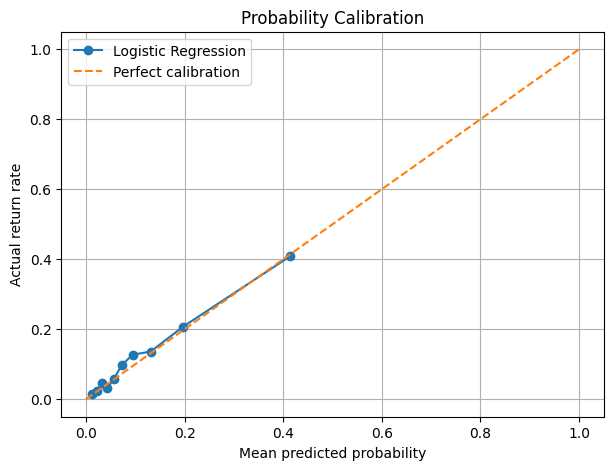

In [27]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

fraction_positive, mean_predicted = calibration_curve(
    y_valid,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

print("Brier Score:", round(brier_score_loss(y_valid, y_prob), 4))

plt.figure(figsize=(7, 5))
plt.plot(mean_predicted, fraction_positive, marker="o", label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual return rate")
plt.title("Probability Calibration")
plt.legend()
plt.grid(True)
plt.show()

compare against bse line brier score

In [28]:
from sklearn.metrics import brier_score_loss

baseline_prob = [y_valid.mean()] * len(y_valid)

print(
    "Baseline Brier Score:",
    round(brier_score_loss(y_valid, baseline_prob), 4)
)

print(
    "Logistic Regression Brier Score:",
    round(brier_score_loss(y_valid, y_prob), 4)
)

Baseline Brier Score: 0.102
Logistic Regression Brier Score: 0.085


Final model traing with LR

In [29]:
# Use all cleaned historical data
X_full = train_enriched[features]
y_full = train_enriched["returned"]

# Train final Logistic Regression model
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

final_model.fit(X_full, y_full)

print("Final model trained successfully!")
print("Training rows:", len(X_full))
print("Features:", len(features))

Final model trained successfully!
Training rows: 10504
Features: 21


In [30]:
# Generate return probabilities for unlabelled orders
test_prob = final_model.predict_proba(test_enriched[features])[:, 1]

print("Predictions generated successfully!")
print("Number of predictions:", len(test_prob))
print("Minimum probability:", round(test_prob.min(), 4))
print("Maximum probability:", round(test_prob.max(), 4))

Predictions generated successfully!
Number of predictions: 2096
Minimum probability: 0.0048
Maximum probability: 0.9816


In [31]:
# Create submission using the sample format
predictions = sample_submission.copy()

# Map predictions to the corresponding order IDs
probability_map = dict(zip(test_enriched["order_id"], test_prob))

predictions["score"] = predictions["order_id"].map(probability_map)

# Validate the output
assert predictions["score"].notna().all()
assert len(predictions) == len(test_enriched)
assert predictions.columns.tolist() == ["order_id", "score"]

# Save file in the project root
# DISABLED: predictions.csv is now produced by train_clean.py (see notes at top).
# predictions.to_csv("../predictions.csv", index=False)

print("predictions.csv created successfully!")
display(predictions.head(10))

predictions.csv created successfully!


,order_id,score
0,KO2610504,0.110657
1,KO2610505,0.057647
2,KO2610506,0.065027
3,KO2610507,0.008878
4,KO2610508,0.012487
5,KO2610509,0.026737
6,KO2610510,0.045290
7,KO2610511,0.228970
8,KO2610512,0.033955
9,KO2610513,0.546373


In [32]:
import joblib

# DISABLED: the model is now built by train_clean.py. Re-running this cell would overwrite it with the old, leakier-feature version.
# joblib.dump(final_model, "../models/returns_risk_model.pkl")

print("Model NOT saved here: use train_clean.py")

Model saved successfully!


validate submission file

In [33]:
import pandas as pd
import os

# Read the saved submission file
submission = pd.read_csv("../predictions.csv")

print("File exists:", os.path.exists("../predictions.csv"))
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Missing values:", submission.isnull().sum().sum())
print("Duplicate order IDs:", submission["order_id"].duplicated().sum())
print("Minimum score:", submission["score"].min())
print("Maximum score:", submission["score"].max())

# Validation checks
assert len(submission) == 2096
assert submission.columns.tolist() == ["order_id", "score"]
assert submission["order_id"].is_unique
assert submission["score"].notna().all()
assert submission["score"].between(0, 1).all()

print("\nAll submission checks passed!")

File exists: True
Rows: 2096
Columns: ['order_id', 'score']
Missing values: 0
Duplicate order IDs: 0
Minimum score: 0.0048016774737189
Maximum score: 0.9815998820743116

All submission checks passed!


In [34]:
print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal features:", len(features))

Numeric features:
['discount_pct', 'qty', 'order_value_inr', 'promised_delivery_days', 'customer_prior_orders', 'customer_prior_returns', 'list_price_inr', 'warranty_months', 'product_age_days', 'order_month', 'order_day_of_week', 'order_hour']

Categorical features:
['payment_mode', 'sales_channel', 'is_gift', 'sku', 'city', 'state', 'shield_member', 'family', 'model_name']

Total features: 21


Catboost

In [35]:
import pandas as pd
import numpy as np

# Same chronological split used for Logistic Regression
split_date = pd.Timestamp("2026-04-01")

X_train_cb = train_enriched.loc[
    train_enriched["order_placed_at"] < split_date, features
].copy()

X_val_cb = train_enriched.loc[
    train_enriched["order_placed_at"] >= split_date, features
].copy()

y_train_cb = train_enriched.loc[
    train_enriched["order_placed_at"] < split_date, "returned"
].astype(int)

y_val_cb = train_enriched.loc[
    train_enriched["order_placed_at"] >= split_date, "returned"
].astype(int)

# Prepare categorical features for CatBoost
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("Missing").astype(str)

# Fill missing numeric values using training medians
for col in numeric_features:
    median_value = X_train_cb[col].median()
    X_train_cb[col] = X_train_cb[col].fillna(median_value)
    X_val_cb[col] = X_val_cb[col].fillna(median_value)

print("Training rows:", len(X_train_cb))
print("Validation rows:", len(X_val_cb))
print("Features:", len(features))

Training rows: 8378
Validation rows: 2126
Features: 21


In [41]:
%pip install catboost
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=800,
    depth=6,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="PRAUC",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

catboost_model.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val_cb),
    early_stopping_rounds=100,
    verbose=100
)

print("CatBoost training completed!")

  Using cached catboost-1.2.10-cp310-cp310-win_amd64.whl.metadata (1.5 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
Using cached catboost-1.2.10-cp310-cp310-win_amd64.whl (100.2 MB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)
Using cached plotly-7.1.0-py3-none-any.whl (9.7 MB)

   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
   ---------------------------------------- 0/3 [plotly]
 


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


0:	learn: 0.2671874	test: 0.2644298	best: 0.2644298 (0)	total: 284ms	remaining: 3m 46s
100:	learn: 0.4452036	test: 0.4083006	best: 0.4083006 (100)	total: 10.6s	remaining: 1m 13s
200:	learn: 0.4943061	test: 0.4063126	best: 0.4094808 (109)	total: 18s	remaining: 53.6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4094807891
bestIteration = 109

Shrink model to first 110 iterations.
CatBoost training completed!


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

cat_prob = catboost_model.predict_proba(X_val_cb)[:, 1]

cat_pred = (cat_prob >= 0.5).astype(int)

print("CATBOOST VALIDATION RESULTS")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_val_cb, cat_pred), 4))
print("Precision:", round(precision_score(y_val_cb, cat_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val_cb, cat_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val_cb, cat_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_cb, cat_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val_cb, cat_prob), 4))
print("Brier Score:", round(brier_score_loss(y_val_cb, cat_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_cb, cat_pred))

print("\nClassification Report:")
print(classification_report(y_val_cb, cat_pred))

CATBOOST VALIDATION RESULTS
---------------------------
Accuracy: 0.8909
Precision: 0.8824
Recall: 0.0612
F1 Score: 0.1145
ROC-AUC: 0.7756
PR-AUC: 0.4106
Brier Score: 0.087

Confusion Matrix:
[[1879    2]
 [ 230   15]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      1881
           1       0.88      0.06      0.11       245

    accuracy                           0.89      2126
   macro avg       0.89      0.53      0.53      2126
weighted avg       0.89      0.89      0.85      2126



In [43]:
thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]

for threshold in thresholds:
    predictions = (cat_prob >= threshold).astype(int)

    precision = precision_score(
        y_val_cb, predictions, zero_division=0
    )
    recall = recall_score(
        y_val_cb, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val_cb, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Flagged: {predictions.sum()} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

Threshold: 0.50 | Flagged: 17 | Precision: 0.882 | Recall: 0.061 | F1: 0.115
Threshold: 0.40 | Flagged: 46 | Precision: 0.696 | Recall: 0.131 | F1: 0.220
Threshold: 0.30 | Flagged: 107 | Precision: 0.551 | Recall: 0.241 | F1: 0.335
Threshold: 0.25 | Flagged: 170 | Precision: 0.471 | Recall: 0.327 | F1: 0.386
Threshold: 0.20 | Flagged: 278 | Precision: 0.388 | Recall: 0.441 | F1: 0.413
Threshold: 0.15 | Flagged: 472 | Precision: 0.297 | Recall: 0.571 | F1: 0.391
Threshold: 0.10 | Flagged: 941 | Precision: 0.194 | Recall: 0.747 | F1: 0.309


In [44]:
catboost_tuned = CatBoostClassifier(
    iterations=1500,
    depth=7,
    learning_rate=0.02,
    loss_function="Logloss",
    eval_metric="PRAUC",
    l2_leaf_reg=8,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

catboost_tuned.fit(
    X_train_cb,
    y_train_cb,
    cat_features=categorical_features,
    eval_set=(X_val_cb, y_val_cb),
    early_stopping_rounds=150,
    verbose=100
)

0:	learn: 0.2670102	test: 0.2653917	best: 0.2653917 (0)	total: 84.2ms	remaining: 2m 6s
100:	learn: 0.4124306	test: 0.3961892	best: 0.3992423 (91)	total: 11.2s	remaining: 2m 35s
200:	learn: 0.4859413	test: 0.4118488	best: 0.4132670 (172)	total: 18.6s	remaining: 2m
300:	learn: 0.5246460	test: 0.4109003	best: 0.4143383 (215)	total: 26s	remaining: 1m 43s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.4143383208
bestIteration = 215

Shrink model to first 216 iterations.


CatBoostClassifier(allow_writing_files=False, depth=7, eval_metric='PRAUC', iterations=1500, l2_leaf_reg=8, learning_rate=0.02, loss_function='Logloss', random_seed=42, verbose=100)

In [45]:
tuned_prob = catboost_tuned.predict_proba(X_val_cb)[:, 1]

print("TUNED CATBOOST RESULTS")
print("----------------------")

print("PR-AUC:", round(
    average_precision_score(y_val_cb, tuned_prob), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_val_cb, tuned_prob), 4
))

print("Brier Score:", round(
    brier_score_loss(y_val_cb, tuned_prob), 4
))

TUNED CATBOOST RESULTS
----------------------
PR-AUC: 0.4155
ROC-AUC: 0.7774
Brier Score: 0.0863


In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:
    predictions = (tuned_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Flagged: {predictions.sum()} | "
        f"Precision: {precision_score(y_val_cb, predictions):.3f} | "
        f"Recall: {recall_score(y_val_cb, predictions):.3f} | "
        f"F1: {f1_score(y_val_cb, predictions):.3f}"
    )

Threshold: 0.10 | Flagged: 850 | Precision: 0.212 | Recall: 0.735 | F1: 0.329
Threshold: 0.15 | Flagged: 452 | Precision: 0.296 | Recall: 0.547 | F1: 0.385
Threshold: 0.20 | Flagged: 269 | Precision: 0.390 | Recall: 0.429 | F1: 0.409
Threshold: 0.25 | Flagged: 178 | Precision: 0.472 | Recall: 0.343 | F1: 0.397
Threshold: 0.30 | Flagged: 124 | Precision: 0.532 | Recall: 0.269 | F1: 0.358
Threshold: 0.40 | Flagged: 49 | Precision: 0.755 | Recall: 0.151 | F1: 0.252
Threshold: 0.50 | Flagged: 23 | Precision: 0.826 | Recall: 0.078 | F1: 0.142


In [47]:
import pandas as pd

thresholds = [0.10, 0.15, 0.20]

RETURN_COST = 1150
CALL_COST = 45
PREVENTION_RATE = 0.35

results = []

for threshold in thresholds:
    selected = tuned_prob >= threshold

    calls = selected.sum()

    # Expected returns prevented by confirmation calls
    prevented_returns = tuned_prob[selected].sum() * PREVENTION_RATE

    estimated_savings = prevented_returns * RETURN_COST
    call_cost = calls * CALL_COST
    net_benefit = estimated_savings - call_cost

    results.append({
        "Threshold": threshold,
        "Orders Called": calls,
        "Expected Returns Prevented": round(prevented_returns, 2),
        "Estimated Savings (₹)": round(estimated_savings, 2),
        "Call Cost (₹)": round(call_cost, 2),
        "Estimated Net Benefit (₹)": round(net_benefit, 2)
    })

catboost_business_results = pd.DataFrame(results)

display(catboost_business_results)

,Threshold,Orders Called,Expected Returns Prevented,Estimated Savings (₹),Call Cost (₹),Estimated Net Benefit (₹)
0,0.10,850,57.86,66541.16,38250,28291.16
1,0.15,452,40.78,46901.80,20340,26561.80
2,0.20,269,29.72,34182.03,12105,22077.03


xgboost

In [52]:
#%pip install xgboost
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    accuracy_score
)

# Account for class imbalance
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=600,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=5,
        scale_pos_weight=scale_pos,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train_cb, y_train_cb)

xgb_prob = xgb_model.predict_proba(X_val_cb)[:, 1]

print("XGBoost RESULTS")
print("----------------")
print("Accuracy:", round(accuracy_score(y_val_cb, xgb_prob >= 0.5), 4))
print("PR-AUC:", round(average_precision_score(y_val_cb, xgb_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_cb, xgb_prob), 4))
print("Brier Score:", round(brier_score_loss(y_val_cb, xgb_prob), 4))

XGBoost RESULTS
----------------
Accuracy: 0.7549
PR-AUC: 0.3606
ROC-AUC: 0.76
Brier Score: 0.1657


In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:
    predictions = (xgb_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Flagged: {predictions.sum()} | "
        f"Precision: {precision_score(y_val_cb, predictions, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val_cb, predictions, zero_division=0):.3f} | "
        f"F1: {f1_score(y_val_cb, predictions, zero_division=0):.3f}"
    )

Threshold: 0.10 | Flagged: 1833 | Precision: 0.129 | Recall: 0.967 | F1: 0.228
Threshold: 0.15 | Flagged: 1646 | Precision: 0.139 | Recall: 0.935 | F1: 0.242
Threshold: 0.20 | Flagged: 1457 | Precision: 0.152 | Recall: 0.902 | F1: 0.260
Threshold: 0.25 | Flagged: 1291 | Precision: 0.166 | Recall: 0.873 | F1: 0.279
Threshold: 0.30 | Flagged: 1114 | Precision: 0.185 | Recall: 0.841 | F1: 0.303
Threshold: 0.40 | Flagged: 807 | Precision: 0.209 | Recall: 0.690 | F1: 0.321
Threshold: 0.50 | Flagged: 568 | Precision: 0.257 | Recall: 0.596 | F1: 0.359


tuning histgradientboosting

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

hist_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [56]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)

hist_model = Pipeline([
    ("preprocessor", hist_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=400,
        learning_rate=0.04,
        max_leaf_nodes=15,
        max_depth=5,
        min_samples_leaf=30,
        l2_regularization=2.0,
        random_state=42,
        class_weight="balanced"
    ))
])

hist_model.fit(X_train_cb, y_train_cb)

hist_prob = hist_model.predict_proba(X_val_cb)[:, 1]

print("TUNED HISTGRADIENTBOOSTING RESULTS")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_val_cb, hist_prob >= 0.5), 4))
print("PR-AUC:", round(average_precision_score(y_val_cb, hist_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val_cb, hist_prob), 4))
print("Brier Score:", round(brier_score_loss(y_val_cb, hist_prob), 4))

TUNED HISTGRADIENTBOOSTING RESULTS
----------------------------------
Accuracy: 0.7709
PR-AUC: 0.3737
ROC-AUC: 0.7691
Brier Score: 0.1594


In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

for threshold in thresholds:
    predictions = (hist_prob >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Flagged: {predictions.sum()} | "
        f"Precision: {precision_score(y_val_cb, predictions, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val_cb, predictions, zero_division=0):.3f} | "
        f"F1: {f1_score(y_val_cb, predictions, zero_division=0):.3f}"
    )

Threshold: 0.10 | Flagged: 1810 | Precision: 0.132 | Recall: 0.976 | F1: 0.233
Threshold: 0.15 | Flagged: 1605 | Precision: 0.143 | Recall: 0.939 | F1: 0.249
Threshold: 0.20 | Flagged: 1413 | Precision: 0.156 | Recall: 0.902 | F1: 0.267
Threshold: 0.25 | Flagged: 1245 | Precision: 0.167 | Recall: 0.849 | F1: 0.279
Threshold: 0.30 | Flagged: 1082 | Precision: 0.185 | Recall: 0.816 | F1: 0.301
Threshold: 0.40 | Flagged: 762 | Precision: 0.227 | Recall: 0.706 | F1: 0.344
Threshold: 0.50 | Flagged: 546 | Precision: 0.278 | Recall: 0.620 | F1: 0.384


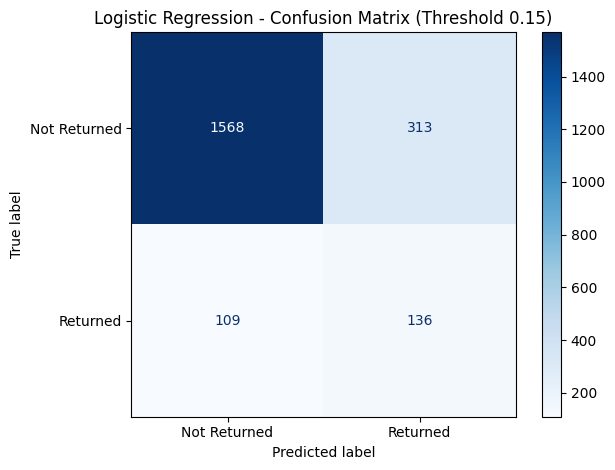

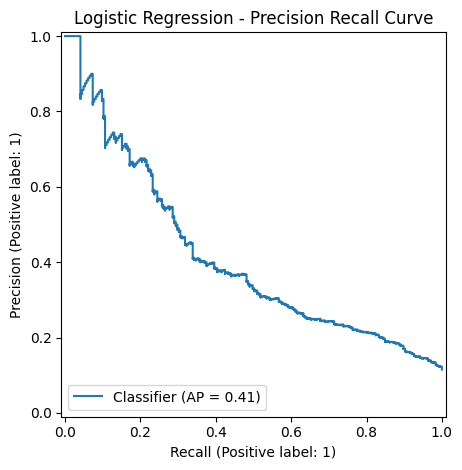

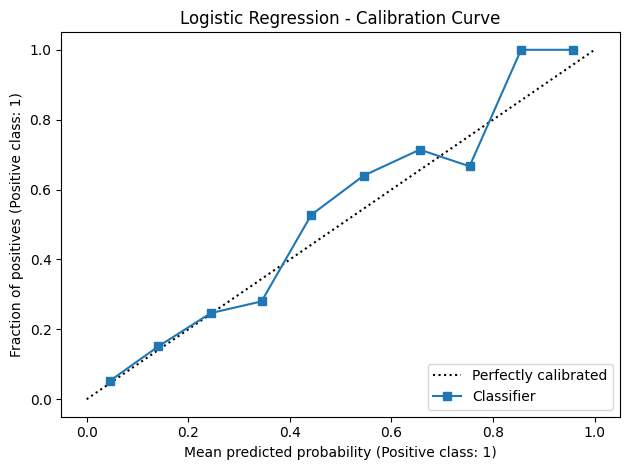

All three evaluation charts saved successfully!


In [58]:
import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)
from sklearn.calibration import CalibrationDisplay

# Create evidence folder if it doesn't exist
os.makedirs("../evidence", exist_ok=True)

# Logistic Regression validation probabilities
lr_prob = model.predict_proba(X_val_cb)[:, 1]

# 1. Confusion Matrix at business threshold 0.15
threshold = 0.15
lr_predictions = (lr_prob >= threshold).astype(int)

cm = confusion_matrix(y_val_cb, lr_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Returned", "Returned"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix (Threshold 0.15)")
plt.tight_layout()
plt.savefig("../evidence/confusion_matrix.png", dpi=300)
plt.show()


# 2. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_val_cb, lr_prob)

plt.title("Logistic Regression - Precision Recall Curve")
plt.tight_layout()
plt.savefig("../evidence/precision_recall_curve.png", dpi=300)
plt.show()


# 3. Calibration Curve
CalibrationDisplay.from_predictions(
    y_val_cb,
    lr_prob,
    n_bins=10,
    strategy="uniform"
)

plt.title("Logistic Regression - Calibration Curve")
plt.tight_layout()
plt.savefig("../evidence/calibration_curve.png", dpi=300)
plt.show()

print("All three evaluation charts saved successfully!")